# Why do the burden model and the GEA see different context compositions?

Reference TEs are **16.1%** of the SV events entering the burden model and **33.3%** of the SVs the GEA
tests. Those are the same variants in the same panel, so the gap is made by the analyses.

**It used to be two things. Now it is one.** Until the 2026-10-01 standardisation the two tracks also
used different context rules — the burden model put TE above promoter with a 2 kb window, the GEA put
promoter above TE with 1 kb — and that difference moved roughly a sixth of all tested SVs. Both now use
**promoter ≤ 1 kb, TE above promoter**, and on the same 20,134 events the two classifiers agree to
within a point on every class:

| | TE | promoter | CDS | intron | UTR | intergenic |
|---|---|---|---|---|---|---|
| burden rule | 33.3 | 19.3 | 9.9 | 9.2 | 4.3 | 24.1 |
| GEA rule | 33.6 | 19.1 | 9.6 | 9.2 | 4.5 | 23.5 |

What is left is the GEA's extra `exon_noncoding` tier (0.6%) and its split of intergenic into proximal
and gene desert — finer labels, not a different ordering.

**Why 1 kb.** The median Arabidopsis gene sits **863 bp** from its nearest upstream neighbour. A 2 kb
promoter window therefore lies inside another gene's body for **73.4%** of genes, against 54.2% at 1 kb.
1 kb is also what TAIR distributes as its standard upstream sequence set.

**So the whole remaining gap is the filters.** The burden model requires an event to be called in
**≥ 90%** of the 231 founders and carried by **≥ 2**; the GEA requires **MAF > 0.05** and a call-rate
floor of **≥ 50%**. Callability is not uniform across the genome, so a call-rate filter is also a
*context* filter — and how much of one depends sharply on where the bar sits, which is what this
notebook measures.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

GS=os.path.abspath(os.path.join(G,"..","..",".."))          # .../analysis/grenenet_selection
E=pd.read_csv(f"{G}/sv_event_catalog.csv"); E["af"]=E.n_carriers/E.n_called.replace(0,np.nan)
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
CC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10","promoter":"#5B7A99","intergenic":"#B9B9B9"}
_c=E.n_called>=0.9*231; _m=E.n_carriers>=2; _c50=E.n_called>=0.5*231
STAGES=[("every SV event",np.ones(len(E),bool)),
        ("≥2 carriers",_m),
        ("called in ≥50%",_m&_c50),
        ("called in ≥90%",_m&_c50&_c)]
GD=pd.read_csv(f"{G}/sv_context_decomposition_gea.csv.gz")
PN=pd.read_csv(f"{G}/sv_context_decomposition_panel.csv.gz")
print(f"event catalogue {len(E):,} SV events   |   GEA-tested SV events {len(GD):,}"
      f"   |   also clearing call rate >=50%: {int(GD.passes_cr50.sum()):,}")


event catalogue 89,940 SV events   |   GEA-tested SV events 27,009   |   also clearing call rate >=50%: 20,134


## 1 · Composition at every filter stage

Each bar is 100% of the events surviving that stage, split by context. The count on the right is how many
events remain. **(b)** is the reason: the share of events in each context that clears each call-rate bar.

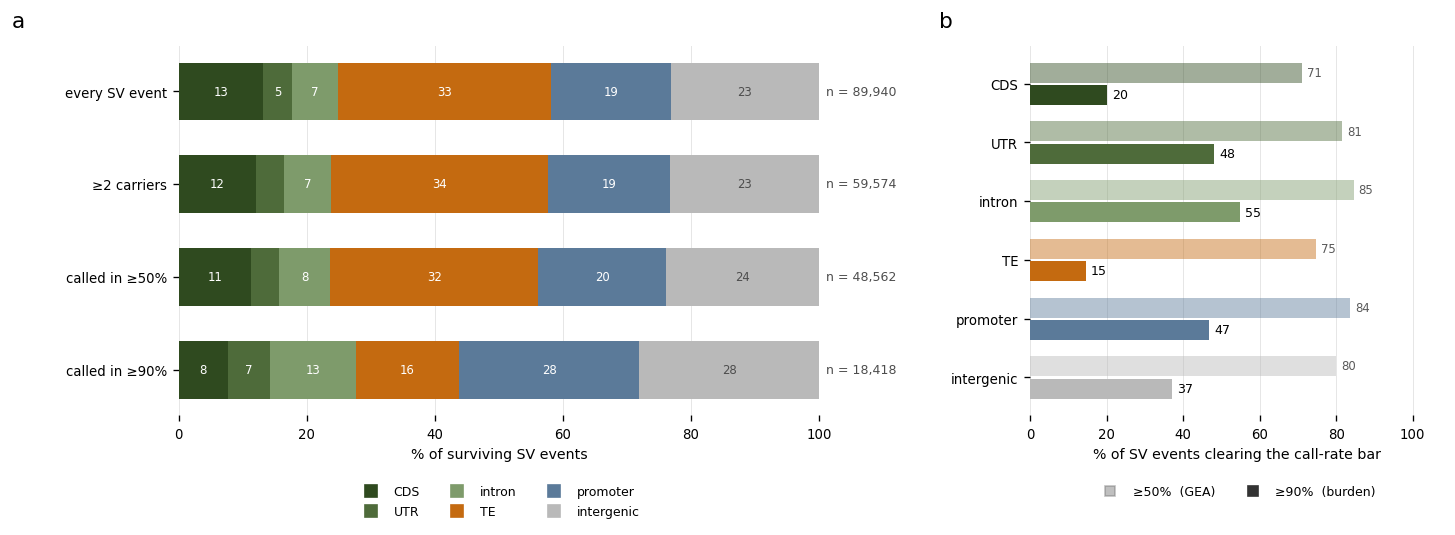

context composition (%) by filter stage:
            every SV event  ≥2 carriers  called in ≥50%  called in ≥90%
context                                                                
CDS                   13.2         12.1            11.2             7.6
UTR                    4.6          4.4             4.5             6.7
intron                 7.1          7.4             7.9            13.3
TE                    33.3         33.9            32.5            16.1
promoter              18.7         18.9            20.0            28.1
intergenic            23.2         23.3            23.9            28.1
n events           89940.0      59574.0         48562.0         18418.0

call rate by context -- share of events clearing each bar:
            >=50%  >=90%
context                 
CDS          71.0   20.1
UTR          81.5   48.1
intron       84.5   54.9
TE           74.7   14.5
promoter     83.6   46.8
intergenic   80.0   37.1


In [3]:

fig,ax=plt.subplots(1,2,figsize=(13.6,4.0),gridspec_kw=dict(width_ratios=[1.55,1],wspace=0.40))
a=ax[0]; style(a)
for i,(lab,m) in enumerate(STAGES):
    comp=E[m].context.value_counts(normalize=True).reindex(CTX).fillna(0)*100; left=0
    for c in CTX:
        a.barh(i,comp[c],left=left,height=0.62,color=CC[c],lw=0)
        if comp[c]>=4.5: a.annotate(f"{comp[c]:.0f}",xy=(left+comp[c]/2,i),ha="center",va="center",
                                     fontsize=7,color="white" if c!="intergenic" else "0.3")
        left+=comp[c]
    a.annotate(f"n = {int(m.sum()):,}",xy=(101,i),va="center",fontsize=7.5,color="0.3",annotation_clip=False)
a.set_yticks(range(len(STAGES))); a.set_yticklabels([s for s,_ in STAGES],fontsize=8); a.invert_yaxis()
a.set_xlim(0,100); a.set_xlabel("% of surviving SV events",fontsize=8.5)
a.annotate("a",xy=(-0.26,1.05),xycoords="axes fraction",fontsize=13)
a.legend([a.plot([],[],"s",color=CC[c],ms=7)[0] for c in CTX],CTX,frameon=False,fontsize=7.5,
         ncol=3,loc="upper center",bbox_to_anchor=(0.5,-0.16))
a=ax[1]; style(a)
cr =(E.assign(_ok=(E.n_called>=0.9*231)).groupby("context")._ok.mean()*100).reindex(CTX)
cr50=(E.assign(_ok=(E.n_called>=0.5*231)).groupby("context")._ok.mean()*100).reindex(CTX)
for i,c in enumerate(CTX):
    a.barh(i-0.19,cr50[c],height=0.34,color=CC[c],lw=0,alpha=0.45)
    a.barh(i+0.19,cr[c],  height=0.34,color=CC[c],lw=0)
    a.annotate(f"{cr50[c]:.0f}",xy=(cr50[c],i-0.19),xytext=(3,0),textcoords="offset points",
               va="center",fontsize=7,color="0.35")
    a.annotate(f"{cr[c]:.0f}",xy=(cr[c],i+0.19),xytext=(3,0),textcoords="offset points",
               va="center",fontsize=7.5)
a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8); a.invert_yaxis(); a.set_xlim(0,108)
a.set_xlabel("% of SV events clearing the call-rate bar",fontsize=8.5)
a.plot([],[],"s",color="0.45",ms=6,alpha=0.45); a.plot([],[],"s",color="0.2",ms=6)
a.legend(["≥50%  (GEA)","≥90%  (burden)"],frameon=False,fontsize=7.5,
         loc="upper center",bbox_to_anchor=(0.5,-0.16),ncol=2)
a.annotate("b",xy=(-0.22,1.05),xycoords="axes fraction",fontsize=13)
save(fig,"sv_context_cascade",nb=True); plt.show()
T=pd.DataFrame({lab:(E[m].context.value_counts(normalize=True).reindex(CTX)*100).round(1)
                for lab,m in STAGES})
T.loc["n events"]=[int(m.sum()) for _,m in STAGES]
print("context composition (%) by filter stage:"); print(T.to_string())
print("\ncall rate by context -- share of events clearing each bar:")
print(pd.DataFrame({">=50%":cr50.round(1),">=90%":cr.round(1)}).to_string())


## 2 · The whole transition, one thing at a time

Both tracks start from the **same** bar and share every step down to *called in ≥ 50%*. Each reported
figure is then that common point plus **one** further filter — the burden's 0.90 call-rate bar, or the
GEA's frequency bar. The italic tag beside each `n` names the single thing that step changed.

There is no context-rule step any more: both tracks use the same rule, so arm B ends at its frequency
filter. The GEA's own labels are shown last for completeness — `exon(nc)` and the proximal / gene-desert
split exist only there, and together they account for under 3% of events.

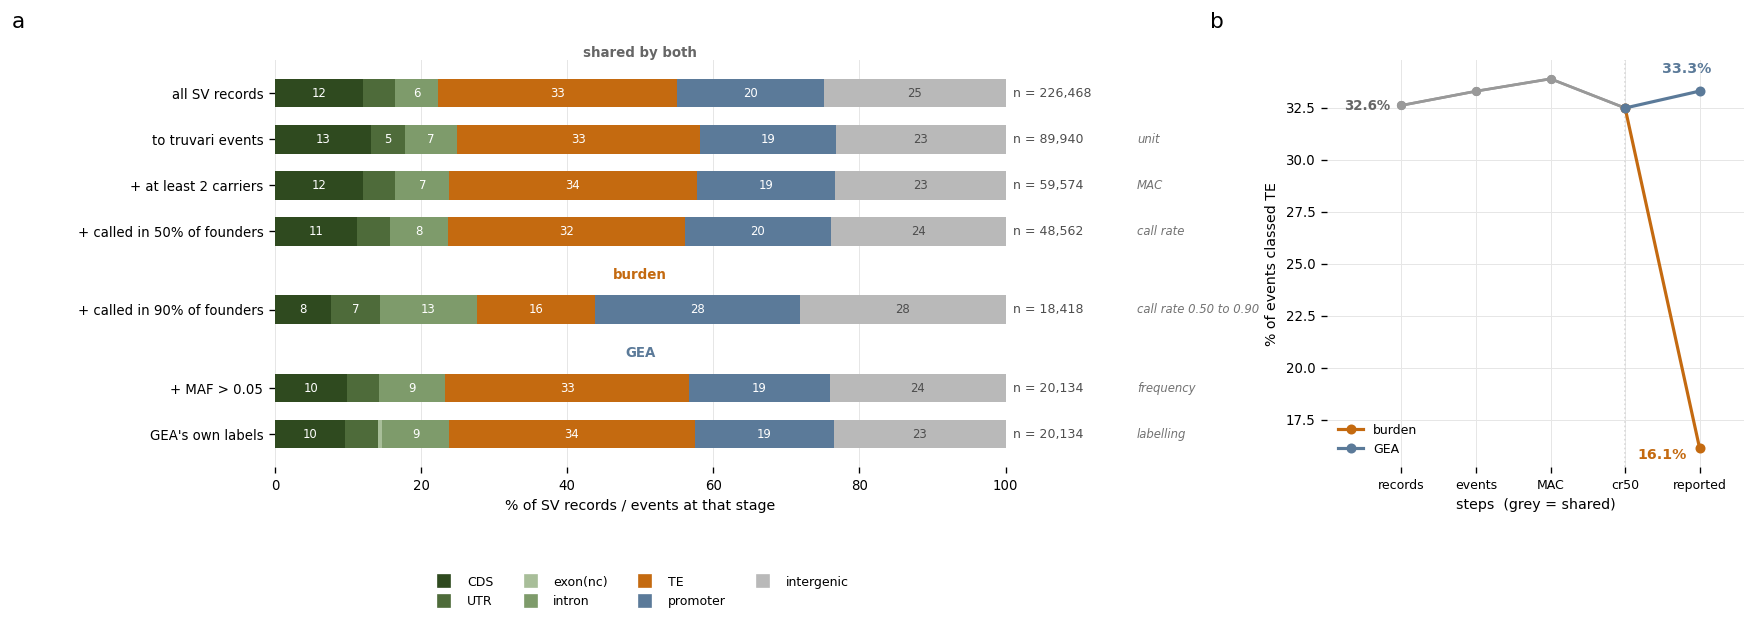

full transition (%):
                              CDS  UTR  exon(nc)  intron    TE  promoter  intergenic       n
all SV records               12.1  4.4       0.0     5.9  32.6      20.2        24.8  226468
to truvari events            13.2  4.6       0.0     7.1  33.3      18.7        23.2   89940
+ at least 2 carriers        12.1  4.4       0.0     7.4  33.9      18.9        23.3   59574
+ called in 50% of founders  11.2  4.5       0.0     7.9  32.5      20.0        23.9   48562
+ called in 90% of founders   7.6  6.7       0.0    13.3  16.1      28.1        28.1   18418
+ MAF > 0.05                  9.9  4.3       0.0     9.2  33.3      19.3        24.1   20134
GEA's own labels              9.6  4.5       0.6     9.2  33.6      19.1        23.5   20134


In [4]:

CTX2=["CDS","UTR","exon(nc)","intron","TE","promoter","intergenic"]
CC2=dict(CC); CC2["exon(nc)"]="#A8BE99"
TMAP={"1_CDS":"CDS","2_UTR":"UTR","3_promoter":"promoter","4_exon_noncoding":"exon(nc)",
      "5_intron":"intron","6_TE":"TE","7_proximal_intergenic":"intergenic","8_gene_desert":"intergenic"}
cmp_=lambda s:(s.value_counts(normalize=True).reindex(CTX2).fillna(0)*100)
EVC=PN.groupby("event").context.first()
_g=GD.passes_cr50.astype(bool)
ARM=[("T","all SV records",cmp_(PN.context),len(PN),None),
     ("T","to truvari events",cmp_(EVC),EVC.size,"unit"),
     ("T","+ at least 2 carriers",cmp_(E[_m].context),int(_m.sum()),"MAC"),
     ("T","+ called in 50% of founders",cmp_(E[_m&_c50].context),int((_m&_c50).sum()),"call rate"),
     ("A","+ called in 90% of founders",cmp_(E[_m&_c50&_c].context),int((_m&_c50&_c).sum()),
      "call rate 0.50 to 0.90"),
     ("B","+ MAF > 0.05",cmp_(GD[_g].context),int(_g.sum()),"frequency"),
     ("B","GEA's own labels",cmp_(GD[_g].tier.map(TMAP)),int(_g.sum()),"labelling")]
YS=[0,1,2,3, 4.7, 6.4,7.4]
fig,ax=plt.subplots(1,2,figsize=(15.8,4.4),gridspec_kw=dict(width_ratios=[1.75,1],wspace=0.56))
a=ax[0]; style(a)
for (arm,lab,c,n,ch),yy in zip(ARM,YS):
    left=0
    for k in CTX2:
        if c[k]<=0: continue
        a.barh(yy,c[k],left=left,height=0.62,color=CC2[k],lw=0)
        if c[k]>=4.5: a.annotate(f"{c[k]:.0f}",xy=(left+c[k]/2,yy),ha="center",va="center",
                                 fontsize=7,color="white" if k!="intergenic" else "0.3")
        left+=c[k]
    a.annotate(f"n = {n:,}",xy=(101,yy),va="center",fontsize=7.5,color="0.3",annotation_clip=False)
    if ch: a.annotate(ch,xy=(118,yy),va="center",fontsize=7,color="0.45",style="italic",
                      annotation_clip=False)
a.set_yticks(YS); a.set_yticklabels([l for _,l,_,_,_ in ARM],fontsize=8); a.invert_yaxis()
a.set_xlim(0,100); a.set_xlabel("% of SV records / events at that stage",fontsize=8.5)
a.annotate("shared by both",xy=(0.5,-0.78),xycoords=("axes fraction","data"),fontsize=8,
           color="0.4",ha="center",fontweight="bold")
a.annotate("burden",xy=(0.5,4.02),xycoords=("axes fraction","data"),fontsize=8,
           color="#C46A10",ha="center",fontweight="bold")
a.annotate("GEA",xy=(0.5,5.72),xycoords=("axes fraction","data"),fontsize=8,
           color="#5B7A99",ha="center",fontweight="bold")
a.annotate("a",xy=(-0.36,1.08),xycoords="axes fraction",fontsize=13)
a.legend([a.plot([],[],"s",color=CC2[k],ms=7)[0] for k in CTX2],CTX2,frameon=False,fontsize=7.5,
         ncol=4,loc="upper center",bbox_to_anchor=(0.5,-0.24))
a=ax[1]; style(a,axis="both")
TR=[i for i,r in enumerate(ARM) if r[0]=="T"]
for arm,col,lab in (("A","#C46A10","burden"),("B","#5B7A99","GEA")):
    idx=TR+[i for i,r in enumerate(ARM) if r[0]==arm]
    xs=list(range(len(idx))); ys=[ARM[i][2]["TE"] for i in idx]
    a.plot(xs[:len(TR)],ys[:len(TR)],"-o",color="0.6",ms=4.5,lw=1.6,zorder=2)
    a.plot(xs[len(TR)-1:len(TR)+1],ys[len(TR)-1:len(TR)+1],"-o",color=col,ms=5,lw=1.9,label=lab,zorder=3)
    a.annotate(f"{ys[len(TR)]:.1f}%",xy=(xs[len(TR)],ys[len(TR)]),xytext=(-8,-4 if arm=="A" else 9),
               textcoords="offset points",ha="right" if arm=="A" else "center",
               va="center" if arm=="A" else "bottom",fontsize=8.5,color=col,fontweight="bold")
yt=[ARM[i][2]["TE"] for i in TR]
a.axvline(len(TR)-1,color="0.85",lw=1,ls=":")
a.annotate(f"{yt[0]:.1f}%",xy=(0,yt[0]),xytext=(-7,0),textcoords="offset points",
           ha="right",va="center",fontsize=8,color="0.4",fontweight="bold")
a.set_xticks(range(len(TR)+1))
a.set_xticklabels(["records","events","MAC","cr50","reported"],fontsize=7.5)
a.set_xlabel("steps  (grey = shared)",fontsize=8.5)
a.set_ylabel("% of events classed TE",fontsize=8.5)
a.set_xlim(-1.0,len(TR)+0.6); a.legend(frameon=False,fontsize=7.5,loc="lower left")
a.annotate("b",xy=(-0.28,1.08),xycoords="axes fraction",fontsize=13)
save(fig,"sv_context_full_transition",nb=True); plt.show()
FT=pd.DataFrame({l:c.round(1) for _,l,c,_,_ in ARM}).T
FT["n"]=[n for _,_,_,n,_ in ARM]
print("full transition (%):"); print(FT.to_string())


## 3 · Reading it

**The call-rate filter is now the whole story, and it is a context filter in disguise.** Reference TEs
are **33.3%** of all SV events but **16.1%** after requiring calls in ≥ 90% of founders — because only
**14.5%** of TE events clear that bar. TE is the worst, but **coding is nearly as bad — 20.1%** — and the
two form a pair well clear of everything else (intergenic 34.2%, promoter 45.7%, UTR 48.1%, intron
54.9%): the gap TE→CDS is 5.5 points, CDS→intergenic is 14.2. So the 0.90 bar is not only a TE filter;
it also discards four fifths of the coding events, which is why the burden model's coding result carries
its own call-rate sensitivity analysis (`sv_burden_callrate.ipynb`).

**Where the bar sits decides whether it is a context filter at all.** At **≥ 50%**, the floor the GEA
applies, TE events clear at **74.7%** — in line with every other context (CDS 71.0%, intergenic 79.2%,
UTR 81.5%, promoter 83.1%, intron 84.5%). At **≥ 90%** TE collapses to 14.5% while intron and UTR stay
near half. That is the quantitative reason the GEA floor was set at 0.50 rather than 0.90: 0.50 removes
the miscalibrated stratum (λ 2.15–2.27 against 1.67–1.80 for well-called records — see
`r2_gea_nonsnp/phase1_replication/multiaxis/callrate_calibration.py`) while leaving the context
composition essentially intact, whereas 0.90 would delete most of the TE class and with it the variation
this project exists to test.

**The context rule is no longer a term.** It used to move about a sixth of all tested SVs. Since both
tracks adopted promoter ≤ 1 kb with TE above promoter they agree to within a point on every class, so a
"TE" bar in the GEA hit landscape and a "TE" bar in the burden counts are now the same category — counted
over different variant sets, but no longer defined differently.

⚠ **They are still not interchangeable, for one reason instead of two.** The GEA's TE share is high
because it retains variants the burden model cannot genotype confidently. That difference is deliberate
on both sides: a per-founder burden needs reliable per-founder genotypes, while the GEA tests frequencies
in pools. If the two are shown side by side, they should be put on one filter set first.

## As run

- **Burden side:** `results/sv_adaptive/sv_event_catalog.csv` — truvari-collapsed SV events with the
  project context rule (`_sv_sfs_context.context`, `PROM_BP = 1000`), `n_called`, `n_carriers`.
- **GEA side:** `results/sv_adaptive/sv_context_decomposition_{panel,gea}.csv.gz`, built by
  `_sv_context_decomposition.py` — the 27,009 SV events clearing MAF > 0.05 in the re-run GEA, carrying
  both the burden rule (`context`) and the GEA rule (`tier`, via `screen_sig_blocks.classify`).
  `passes_cr50` marks the 20,134 that also clear the call-rate floor; their `n_called` is the burden
  catalogue's own, so both arms use one definition of "called".
- **The context rule was standardised on 2026-10-01**: promoter ≤ 1 kb (was 2 kb on the burden side) and
  TE above promoter (was promoter above TE on the GEA side). Both constants are now named —
  `_sv_sfs_context.PROM_BP` and `screen_sig_blocks.PROM_BP` — and the decomposition asserts they agree.
  Narrowing the window moves events only between promoter and intergenic; CDS, UTR, intron and TE
  assignments are unchanged, so the burden model's coding result is unaffected by the change.
- **The unit is not a difference.** Both arms are truvari events. Collapsing is nearly flat across
  contexts (intron 2.08, CDS 2.31, UTR 2.43, TE 2.47, intergenic 2.66, promoter 2.74 alleles/event).